In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import sys
import json
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import *
import copy

sys.path.insert(0, "..")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from numeric_method.numeric_method import solve_navier_stokes
from modeling.data import geometry_to_mtx

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

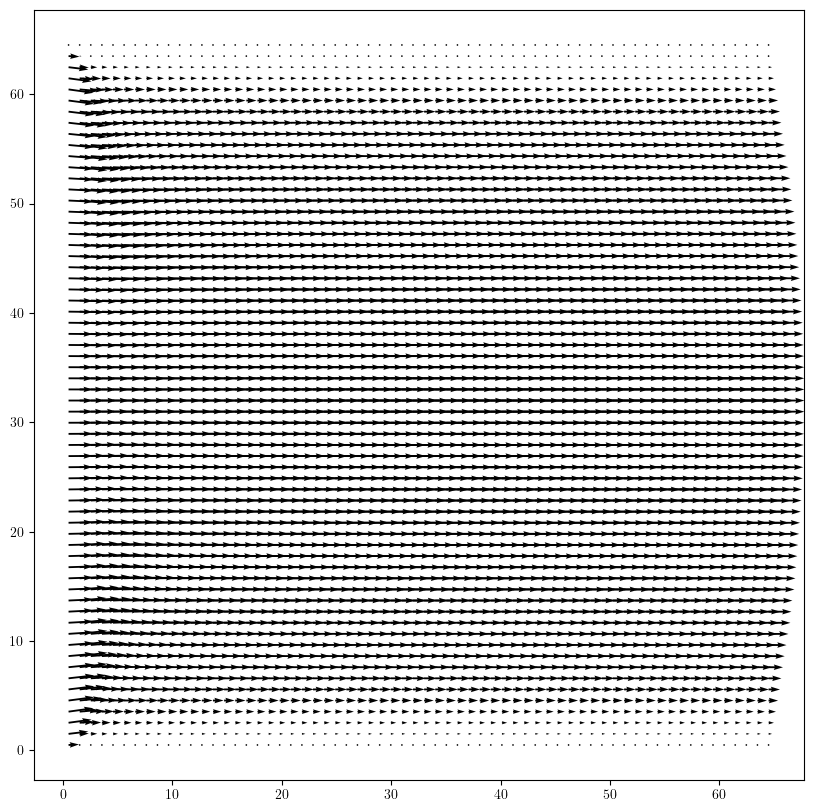

In [2]:
ux = np.load("../../data/CFDBench/tube/bc/case0010/u.npy") 
uy = np.load("../../data/CFDBench/tube/bc/case0010/v.npy")
with open("../../data/CFDBench/tube/bc/case0010/case.json", "r") as f:
    case_ = json.load(f)

with open("../../data/cases/pipe.json", "r") as f:
    case_nm = json.load(f)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_velocity(ax, ux[-1], uy[-1], scale=0.5)
plt.show()

In [66]:
case_

{'height': 0.1, 'width': 1, 'vel_in': 1.1, 'density': 100, 'viscosity': 0.1}

In [67]:
case_nm

{'width': 64,
 'height': 64,
 'dx': 0.05,
 'dy': 0.05,
 'iterations': 1000,
 'time_step': 0.1,
 'density': 100,
 'viscosity': 0.1,
 'beta': 1,
 'geometry': [{'type': 'inflow',
   'pos': {'x': 0, 'y': 1},
   'size': {'width': 1, 'height': 62},
   'vel': {'x': 0.2, 'y': 0}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': 1}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': -1},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': -1}},
  {'type': 'outflow',
   'pos': {'x': -1, 'y': 1},
   'size': {'width': 1, 'height': 62},
   'dir': {'x': -1, 'y': 0}}]}

In [17]:
height_phys = case_["height"]
width_phys = case_["width"]
inflow = case_["vel_in"]
density = case_["density"]
viscosity = case_["viscosity"]

height_px = np.shape(ux)[1]
width_px = np.shape(ux)[2]

dy = height_phys / height_px
dx = width_phys / width_px

case_nm["width"] = width_px
case_nm["height"] = height_px
case_nm["dx"] = dx
case_nm["dy"] = dy
case_nm["density"] = density
case_nm["viscosity"] = viscosity

C = 10
case_nm["time_step"] = 1 #np.max([dy, dx]) * C / inflow

for gi in range(len(case_nm["geometry"])):
    if case_nm["geometry"][gi]["type"] == "inflow":
        case_nm["geometry"][gi]["vel"]["x"] = inflow
        break

In [4]:
case_nm

{'width': 64,
 'height': 64,
 'dx': 0.015625,
 'dy': 0.0015625,
 'iterations': 1000,
 'time_step': 0.14204545454545453,
 'density': 100,
 'viscosity': 0.1,
 'beta': 1,
 'geometry': [{'type': 'wall',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': 1}},
  {'type': 'wall',
   'pos': {'x': 0, 'y': -1},
   'size': {'width': -1, 'height': 1},
   'dir': {'x': 0, 'y': -1}},
  {'type': 'outflow',
   'pos': {'x': -1, 'y': 0},
   'size': {'width': 1, 'height': 64},
   'dir': {'x': -1, 'y': 0}},
  {'type': 'inflow',
   'pos': {'x': 0, 'y': 0},
   'size': {'width': 1, 'height': 64},
   'vel': {'x': 1.1, 'y': 0}}]}

In [18]:
u, p, u_star, div_u_star, phi = solve_navier_stokes(
    width_px,
    height_px,
    dx,
    dy,
    case_nm["iterations"],
    case_nm["time_step"],
    density,
    viscosity,
    1,
    case_nm["geometry"],
    dynamic_time_step=True,
    implicit_laplacian=True,
    return_div_u_star=True,
    method_type="numeric"
)

	 -> Creating discrete Poisson matrix...


     : 100%|██████████| 64/64 [00:00<00:00, 1160.35it/s]


	 -> Converting to a sparse matrix...
	 -> Done!

	 -> Creating discrete Laplacian matrix...
	 -> Converting to a sparse matrix...
	 -> Done!
	 -> Iterating...


     : 100%|██████████| 1000/1000 [00:51<00:00, 19.27it/s]


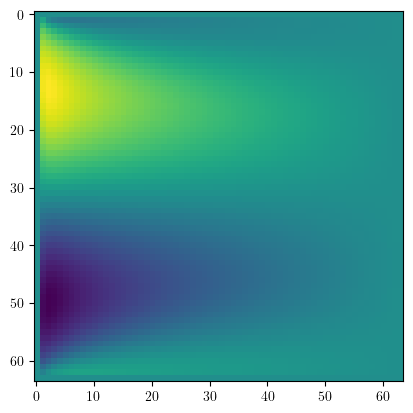

In [6]:
plt.imshow(u[-1][:, :, 1])
plt.show()

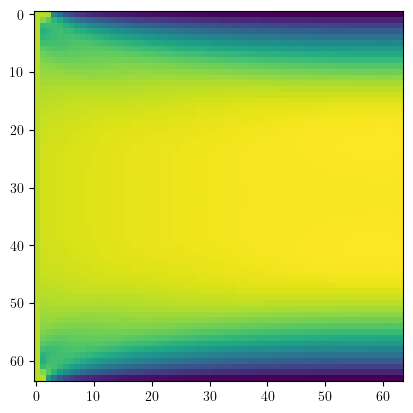

In [7]:
plt.imshow(u[-1][:, :, 0])
plt.show()

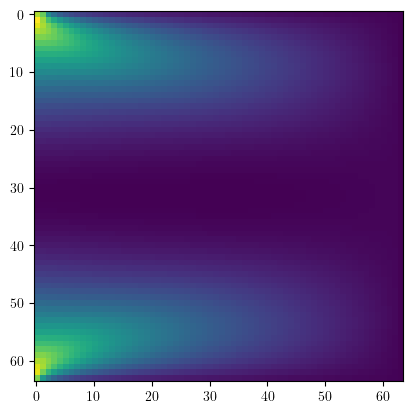

In [8]:
plt.imshow(p[-1])
plt.show()

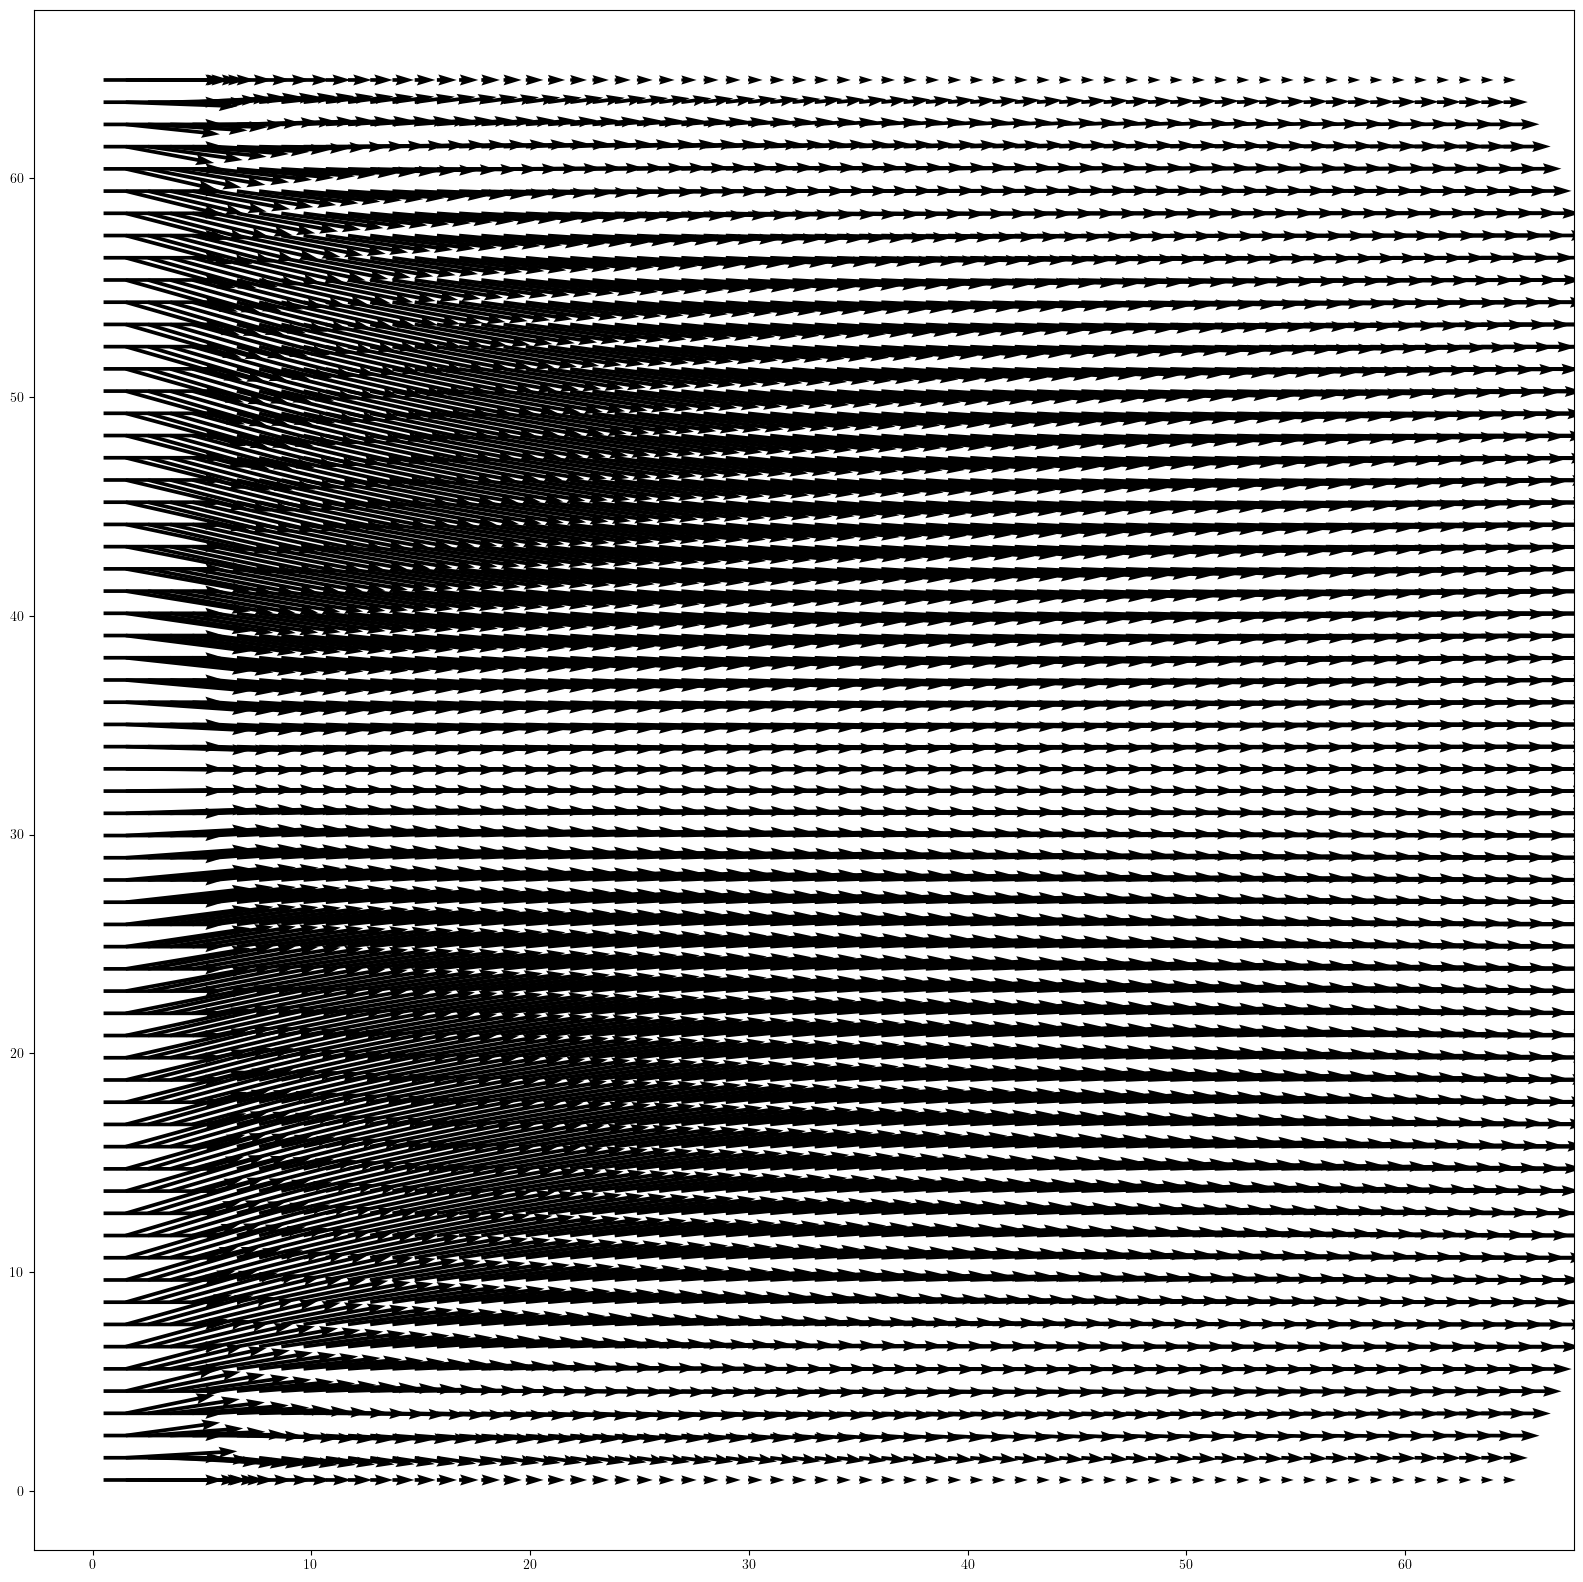

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(20, 20))
plot_velocity(ax, u[-1][:, :, 0], u[-1][:, :, 1], scale=0.2)
plt.show()

In [10]:
u_nm = np.transpose(u[-1], (2, 0, 1))

u_baseline = np.stack([ux[-1], uy[-1]], axis=0)

print(u_nm.shape)
print(u_baseline.shape)

(2, 64, 64)
(2, 64, 64)


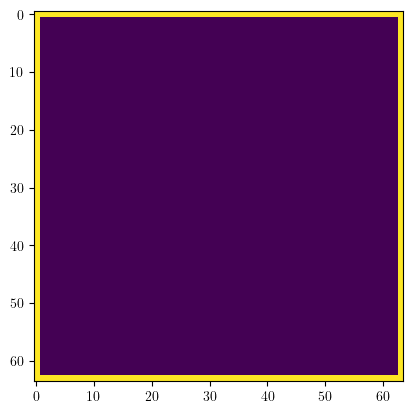

In [11]:
_, _, _, _, _, _, boundary = geometry_to_mtx(case_nm["geometry"], width_px, height_px)
plt.imshow(boundary)
plt.show()

In [12]:
print(f"{np.mean(u_nm)} +- {np.std(u_nm)}")
print(f"{np.mean(u_baseline)} +- {np.std(u_baseline)}")

0.49995374856963665 +- 0.5439114061390387
0.5368420381576523 +- 0.6356829956520839


0.2191532341367204


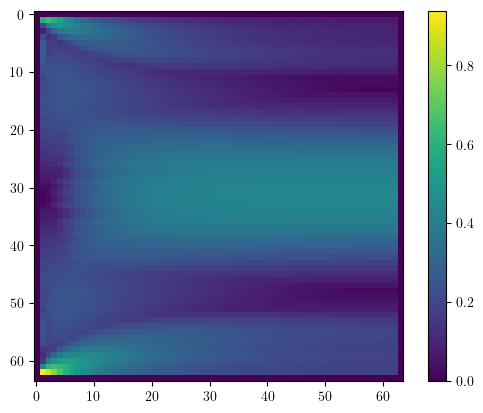

In [13]:
err_vec_inf = pointwise_inf(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_inf))

plt.imshow(err_vec_inf)
plt.colorbar()
plt.show()

0.16412199629069968


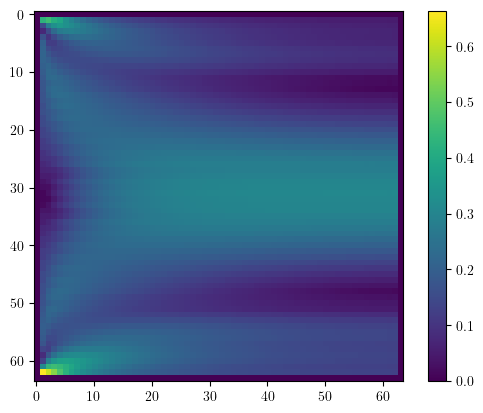

In [14]:
err_vec_2 =  pointwise_rmse(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_2))

plt.imshow(err_vec_2)
plt.colorbar()
plt.show()

0.13695450718355115


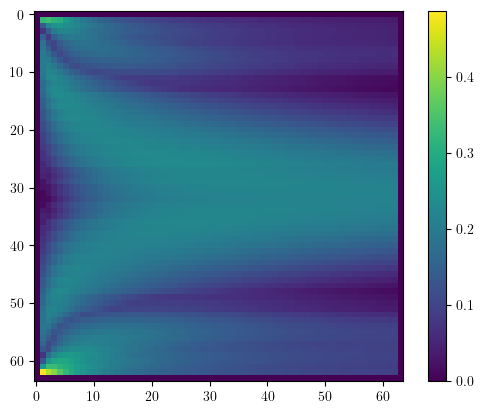

In [15]:
err_vec_1 = pointwise_l1(u_baseline, u_nm) * (1 - boundary)
print(np.mean(err_vec_1))

plt.imshow(err_vec_1)
plt.colorbar()
plt.show()

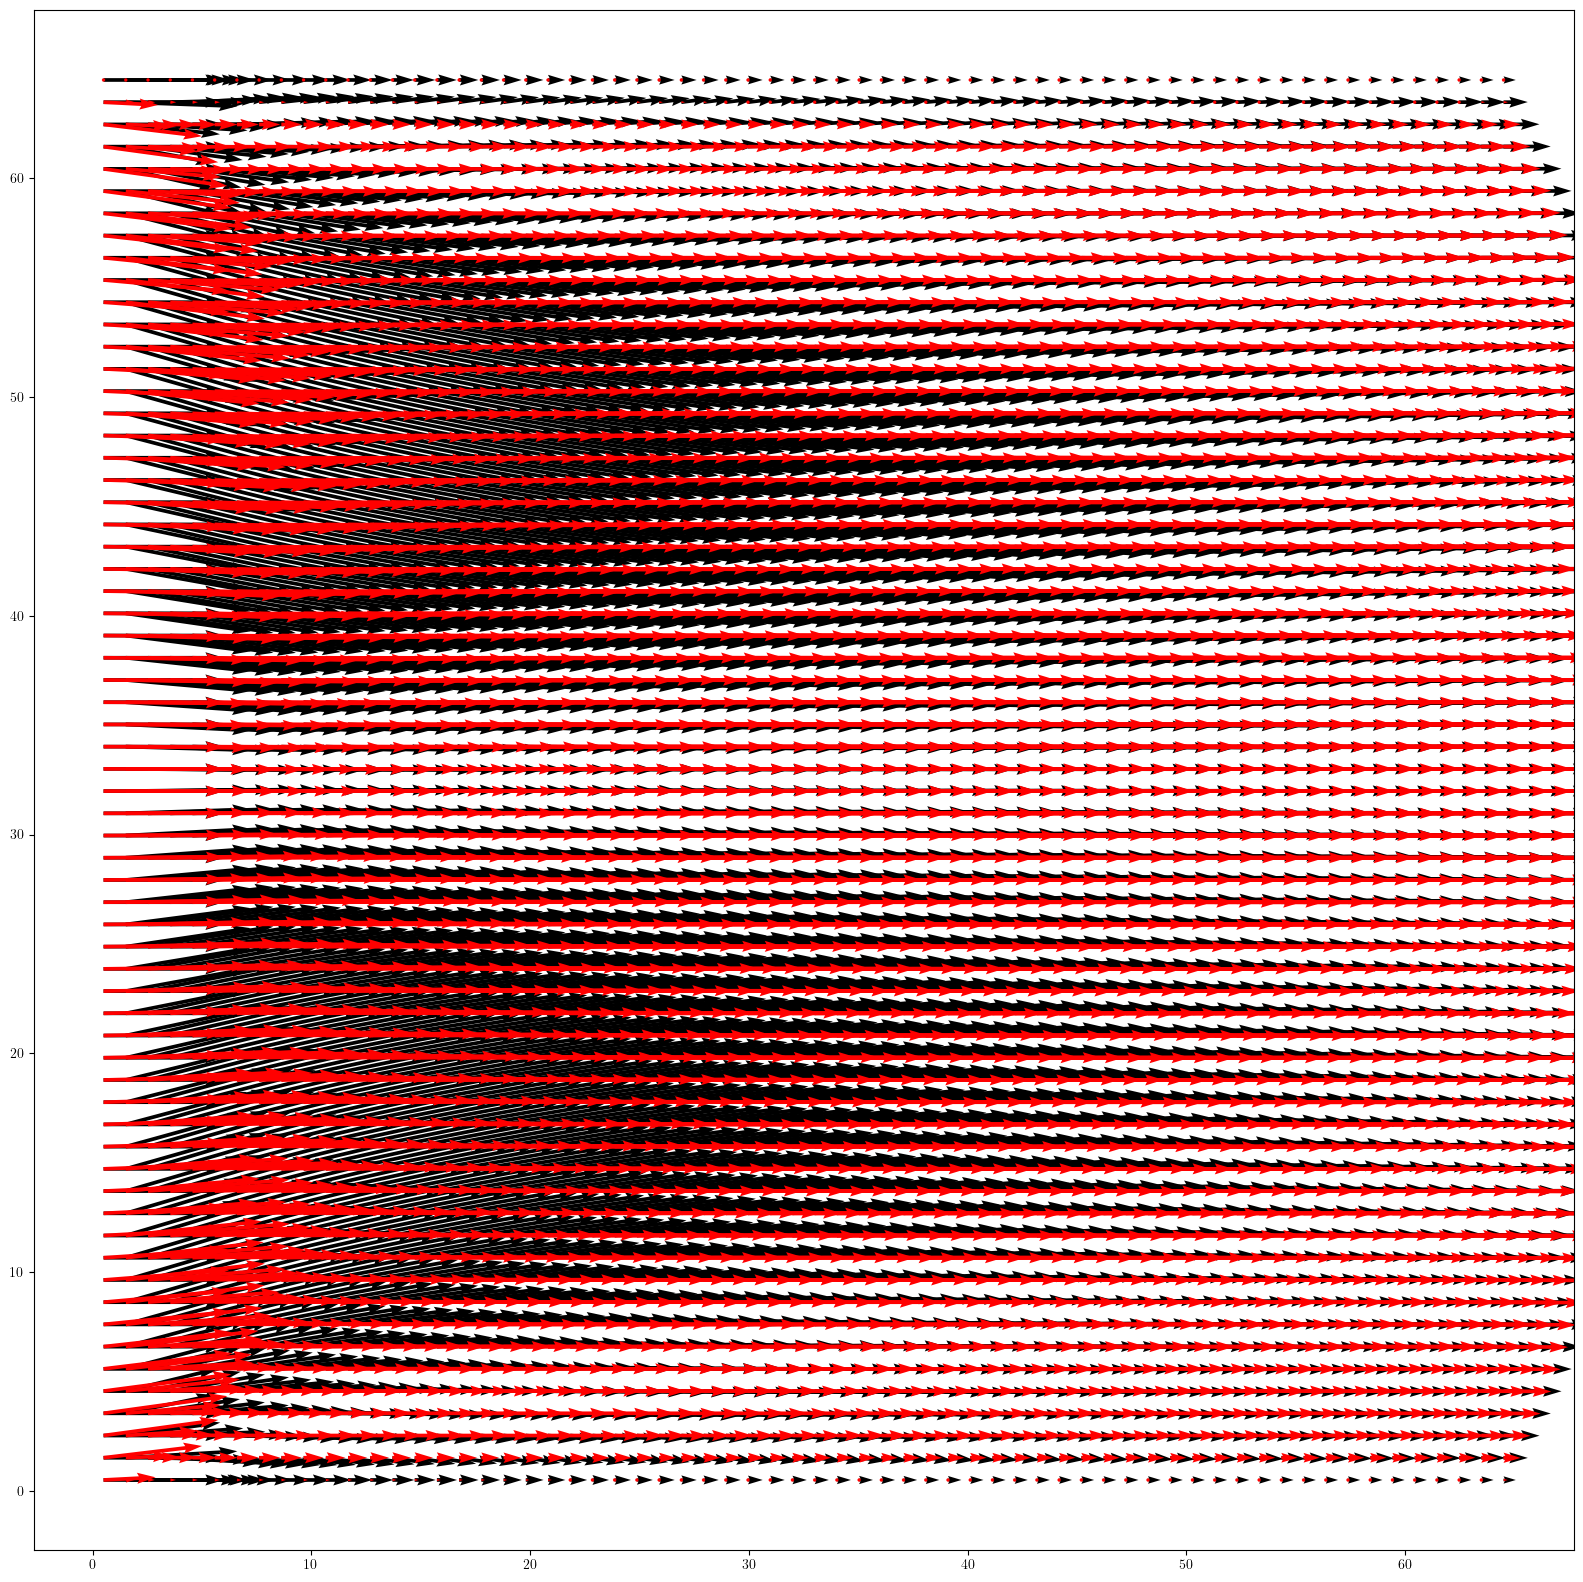

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(20, 20))
plot_velocity(ax, u_nm[0, :, :], u_nm[1, :, :], scale=0.2)
plot_velocity(ax, u_baseline[0, :, :], u_baseline[1, :, :], scale=0.2, color="red")
plt.show()